<a href="https://colab.research.google.com/github/Maybe1Harsh/indian-market-spiderweb/blob/main/indian_market_spiderweb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
!pip install yfinance

In [24]:
import matplotlib.pyplot as plt


In [25]:
import yfinance as yf, pandas as pd, numpy as np

In [26]:
tickers = [
    "HDFCBANK.NS",
    "ICICIBANK.NS",
    "SBIN.NS",
    "AXISBANK.NS",
    "KOTAKBANK.NS",
    "BAJFINANCE.NS",
    "BAJAJFINSV.NS",
    "CHOLAFIN.NS",
    "MUTHOOTFIN.NS",
    "PAYTM.NS",
]


In [27]:
prices = yf.download(tickers, start="2021-01-01", auto_adjust=True)["Close"]

[*********************100%***********************]  10 of 10 completed


In [28]:
returns = np.log(prices / prices.shift(1)).dropna(how="all")
corr = returns.corr()


In [29]:
prices.to_csv("prices.csv")
returns.to_csv("returns.csv")
print(corr.round(2))

Ticker         AXISBANK.NS  BAJAJFINSV.NS  BAJFINANCE.NS  CHOLAFIN.NS  \
Ticker                                                                  
AXISBANK.NS           1.00           0.44           0.43         0.40   
BAJAJFINSV.NS         0.44           1.00           0.78         0.50   
BAJFINANCE.NS         0.43           0.78           1.00         0.54   
CHOLAFIN.NS           0.40           0.50           0.54         1.00   
HDFCBANK.NS           0.46           0.40           0.43         0.36   
ICICIBANK.NS          0.61           0.45           0.45         0.39   
KOTAKBANK.NS          0.42           0.39           0.41         0.33   
MUTHOOTFIN.NS         0.29           0.35           0.35         0.38   
PAYTM.NS              0.18           0.20           0.23         0.27   
SBIN.NS               0.55           0.44           0.44         0.37   

Ticker         HDFCBANK.NS  ICICIBANK.NS  KOTAKBANK.NS  MUTHOOTFIN.NS  \
Ticker                                            

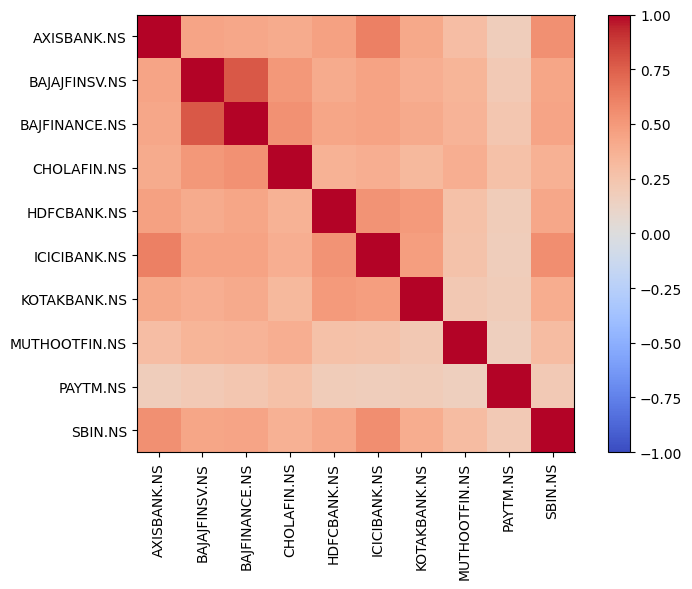

In [30]:
plt.figure(figsize=(8,6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar()
plt.tight_layout()
plt.savefig("corr_heatmap.png", dpi=150)
plt.show()